# 04 - Evaluación final con los datos de la ENDES 2025

Corresponde a la etapa de **Evaluación** del proceso CRISP-DM y a los **objetivos específicos 2 y 3**. Aplica la sección 7 de `docs/protocolo_analisis.md`.

- Los modelos, hiperparámetros y umbrales se congelaron en el notebook 03 (`models/v2/`, commit registrado en cada modelo).
- Esta es la **única ejecución** sobre los datos 2025. El notebook registra la ejecución en `resultados/04_evaluacion/registro_ejecucion.json` (fecha, commit y huellas SHA-256 de los modelos y de los datos) y se detiene si ese registro ya existe.
- Todas las métricas se interpretan como **concordancia con el diagnóstico autorreportado** (QS109), no como detección de diabetes.

In [1]:
import hashlib
import json
import subprocess
from datetime import datetime
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score

from preparacion import DESENLACE, codificar

pd.set_option('display.float_format', '{:.4f}'.format)

MODELOS = Path('../models/v2')
DATOS_EVALUACION = Path('../data/processed/endes_lima_evaluacion_2025.csv')
SALIDA = Path('../resultados/04_evaluacion')
REGISTRO = SALIDA / 'registro_ejecucion.json'
PREVALENCIA_DESARROLLO = 562 / 8909  # modelo nulo: prevalencia de 2021-2024 (notebook 01)
SEMILLA, N_BOOTSTRAP = 42, 2000

if REGISTRO.exists():
    raise RuntimeError(f'La evaluación final ya se ejecutó (ver {REGISTRO}). El protocolo permite una sola ejecución.')

estado_git = subprocess.run(['git', 'status', '--porcelain', '--', str(MODELOS)], capture_output=True, text=True).stdout
if estado_git.strip():
    raise RuntimeError('Los modelos de models/v2 tienen cambios sin commit; no se puede garantizar que estén congelados.')
commit = subprocess.run(['git', 'rev-parse', '--short', 'HEAD'], capture_output=True, text=True).stdout.strip()
print('Commit de los modelos congelados:', commit)

Commit de los modelos congelados: a886bc7


## Carga de los modelos congelados y de los datos 2025

In [2]:
def sha256(ruta):
    return hashlib.sha256(Path(ruta).read_bytes()).hexdigest()


artefactos = {}
for ruta in sorted(MODELOS.glob('*.joblib')):
    a = joblib.load(ruta)
    artefactos[(a['version'], a['algoritmo'])] = a | {'archivo': ruta.name, 'sha256': sha256(ruta)}

e = codificar(pd.read_csv(DATOS_EVALUACION))
assert (e['anio'] == 2025).all()
y = e[DESENLACE].astype(int).to_numpy()

SALIDA.mkdir(parents=True, exist_ok=True)
registro = {
    'fecha_ejecucion': datetime.now().isoformat(timespec='seconds'),
    'commit': commit,
    'datos_evaluacion_sha256': sha256(DATOS_EVALUACION),
    'modelos': {a['archivo']: a['sha256'] for a in artefactos.values()},
}
print(f'Evaluación 2025: {len(y)} registros, {y.sum()} con diagnóstico autorreportado ({100 * y.mean():.2f}%)')
pd.DataFrame([{'archivo': a['archivo'], 'version': v, 'algoritmo': n, 'seleccionado': a['seleccionado'], 'umbral': a['umbral']}
              for (v, n), a in artefactos.items()])

Evaluación 2025: 1990 registros, 136 con diagnóstico autorreportado (6.83%)


,archivo,version,algoritmo,seleccionado,umbral
0,completo_lightgbm.joblib,completo,LightGBM,False,0.0622
1,completo_random_forest.joblib,completo,Random Forest,False,0.0556
2,completo_regresion_logistica.joblib,completo,Regresión logística,True,0.0589
3,completo_xgboost.joblib,completo,XGBoost,False,0.0697
4,web_lightgbm.joblib,web,LightGBM,False,0.0705
5,web_random_forest.joblib,web,Random Forest,False,0.0753
6,web_regresion_logistica.joblib,web,Regresión logística,True,0.0599
7,web_xgboost.joblib,web,XGBoost,False,0.0731


In [3]:
pred = {clave: a['modelo'].predict_proba(e[a['predictores']])[:, 1] for clave, a in artefactos.items()}

## Métricas de desempeño

- AUC-ROC y AUC-PR con intervalos de confianza al 95% por bootstrap (2,000 remuestreos).
- Sensibilidad, especificidad y valores predictivos en el umbral congelado.
- Brier score frente al modelo nulo (prevalencia de 2021–2024).
- Pendiente de calibración (con IC 95%) e intercepto de calibración.
- Estabilidad temporal: AUC de validación cruzada (2021–2024) menos AUC de 2025.

In [4]:
def ic_bootstrap(metrica, y_real, p):
    rng = np.random.default_rng(SEMILLA)  # mismos remuestreos para todos los modelos de un mismo conjunto
    indices = rng.integers(0, len(y_real), (N_BOOTSTRAP, len(y_real)))
    valores = [metrica(y_real[i], p[i]) for i in indices if 0 < y_real[i].sum() < len(i)]
    return np.percentile(valores, [2.5, 97.5])


def calibracion(y_real, p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    lp = np.log(p / (1 - p))
    ajuste = sm.Logit(y_real, sm.add_constant(lp)).fit(disp=False)
    pendiente, (ic_inf, ic_sup) = ajuste.params[1], ajuste.conf_int()[1]
    intercepto = sm.GLM(y_real, np.ones(len(lp)), offset=lp, family=sm.families.Binomial()).fit().params[0]
    return pendiente, ic_inf, ic_sup, intercepto


def clasificacion(y_real, p, umbral):
    positivo = p >= umbral
    vp, fp = (positivo & (y_real == 1)).sum(), (positivo & (y_real == 0)).sum()
    vn, fn = (~positivo & (y_real == 0)).sum(), (~positivo & (y_real == 1)).sum()
    return {'sensibilidad': vp / (vp + fn), 'especificidad': vn / (vn + fp), 'VPP': vp / (vp + fp), 'VPN': vn / (vn + fn)}


def metricas(y_real, p, artefacto):
    auc = roc_auc_score(y_real, p)
    auc_ic = ic_bootstrap(roc_auc_score, y_real, p)
    ap = average_precision_score(y_real, p)
    ap_ic = ic_bootstrap(average_precision_score, y_real, p)
    pendiente, pend_inf, pend_sup, intercepto = calibracion(y_real, p)
    return {
        'AUC_ROC': auc, 'AUC_ROC_IC95': f'{auc_ic[0]:.3f}–{auc_ic[1]:.3f}',
        'AUC_PR': ap, 'AUC_PR_IC95': f'{ap_ic[0]:.3f}–{ap_ic[1]:.3f}',
        **clasificacion(y_real, p, artefacto['umbral']),
        'Brier': brier_score_loss(y_real, p),
        'Brier_nulo': brier_score_loss(y_real, np.full(len(y_real), PREVALENCIA_DESARROLLO)),
        'pendiente_calibracion': pendiente, 'pendiente_IC95': f'{pend_inf:.2f}–{pend_sup:.2f}',
        'intercepto_calibracion': intercepto,
        'AUC_CV_2021_2024': artefacto['auc_cv'],
        'diferencia_AUC_CV_menos_2025': artefacto['auc_cv'] - auc,
    }


resultados = pd.DataFrame([
    {'version': v, 'algoritmo': n, 'seleccionado': a['seleccionado'], **metricas(y, pred[(v, n)], a)}
    for (v, n), a in artefactos.items()
]).sort_values(['version', 'algoritmo'])
resultados.to_csv(SALIDA / 'metricas_2025.csv', index=False)
resultados

,version,algoritmo,seleccionado,AUC_ROC,AUC_ROC_IC95,AUC_PR,AUC_PR_IC95,sensibilidad,especificidad,VPP,VPN,Brier,Brier_nulo,pendiente_calibracion,pendiente_IC95,intercepto_calibracion,AUC_CV_2021_2024,diferencia_AUC_CV_menos_2025
0,completo,LightGBM,False,0.7841,0.745–0.823,0.2347,0.179–0.308,0.7574,0.6904,0.1521,0.9749,0.0581,0.0637,0.9887,0.82–1.16,0.0349,0.7763,-0.0078
1,completo,Random Forest,False,0.7909,0.751–0.830,0.2295,0.178–0.299,0.7353,0.7141,0.1587,0.9735,0.0581,0.0637,1.0224,0.86–1.19,0.0606,0.7815,-0.0093
2,completo,Regresión logística,True,0.7961,0.755–0.835,0.2320,0.181–0.299,0.7426,0.7184,0.1621,0.9744,0.0578,0.0637,1.0202,0.85–1.19,0.0419,0.7828,-0.0133
3,completo,XGBoost,False,0.7958,0.758–0.833,0.2404,0.185–0.311,0.7574,0.7109,0.1612,0.9756,0.0577,0.0637,1.0335,0.86–1.21,0.0339,0.7823,-0.0134
4,web,LightGBM,False,0.7825,0.743–0.821,0.2265,0.173–0.298,0.7500,0.7141,0.1614,0.9750,0.0586,0.0637,0.9579,0.79–1.13,0.0436,0.7768,-0.0057
5,web,Random Forest,False,0.7776,0.735–0.817,0.2170,0.166–0.284,0.7500,0.7157,0.1622,0.9750,0.0584,0.0637,1.0018,0.82–1.18,0.0485,0.7798,0.0022
6,web,Regresión logística,True,0.7977,0.757–0.835,0.2353,0.182–0.303,0.7426,0.7309,0.1683,0.9748,0.0579,0.0637,1.0087,0.84–1.18,0.0572,0.7815,-0.0162
7,web,XGBoost,False,0.7901,0.750–0.827,0.2253,0.175–0.298,0.7353,0.7195,0.1613,0.9737,0.0580,0.0637,1.0063,0.83–1.18,0.0426,0.7795,-0.0105


## Comparación de algoritmos con la regresión logística (HE2)

Prueba de DeLong bilateral para AUC-ROC correlacionadas (mismos registros), implementada según el algoritmo rápido de Sun y Xu (2014).

In [5]:
def _rangos_medios(x):
    orden = np.argsort(x)
    z = x[orden]
    n = len(x)
    t = np.zeros(n)
    i = 0
    while i < n:
        j = i
        while j < n and z[j] == z[i]:
            j += 1
        t[i:j] = 0.5 * (i + j - 1) + 1
        i = j
    rangos = np.empty(n)
    rangos[orden] = t
    return rangos


def delong(y_real, p1, p2):
    positivos, negativos = y_real == 1, y_real == 0
    m, n = positivos.sum(), negativos.sum()
    pred = np.vstack([p1, p2])
    tx = np.array([_rangos_medios(k[positivos]) for k in pred])
    ty = np.array([_rangos_medios(k[negativos]) for k in pred])
    tz = np.array([_rangos_medios(np.concatenate([k[positivos], k[negativos]])) for k in pred])
    aucs = tz[:, :m].sum(axis=1) / m / n - (m + 1) / 2 / n
    v01 = (tz[:, :m] - tx) / n
    v10 = 1 - (tz[:, m:] - ty) / m
    cov = np.cov(v01) / m + np.cov(v10) / n
    var = cov[0, 0] + cov[1, 1] - 2 * cov[0, 1]
    z = (aucs[0] - aucs[1]) / np.sqrt(var)
    return aucs[0] - aucs[1], 2 * stats.norm.sf(abs(z))


filas = []
for (version, nombre) in artefactos:
    if nombre == 'Regresión logística':
        continue
    dif, p = delong(y, pred[(version, nombre)], pred[(version, 'Regresión logística')])
    filas.append({'version': version, 'algoritmo': nombre, 'AUC_algoritmo_menos_AUC_RL': dif, 'p_DeLong': p,
                  'diferencia_significativa': 'Sí' if p < 0.05 else 'No'})
he2 = pd.DataFrame(filas).sort_values(['version', 'algoritmo'])
he2.to_csv(SALIDA / 'he2_delong.csv', index=False)
he2

,version,algoritmo,AUC_algoritmo_menos_AUC_RL,p_DeLong,diferencia_significativa
0,completo,LightGBM,-0.0120,0.1514,No
1,completo,Random Forest,-0.0052,0.5556,No
2,completo,XGBoost,-0.0003,0.9637,No
3,web,LightGBM,-0.0152,0.0370,Sí
4,web,Random Forest,-0.0201,0.0148,Sí
5,web,XGBoost,-0.0076,0.1865,No


## Curvas de calibración de los modelos seleccionados

Proporción observada de diagnóstico autorreportado frente a la probabilidad media predicha, por deciles de probabilidad.

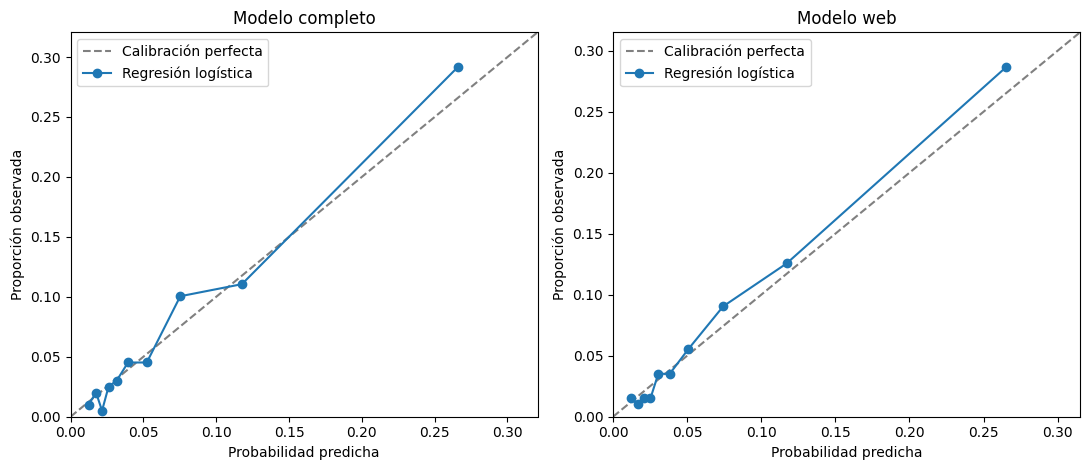

In [6]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 4.8))
for eje, version in zip(ejes, ['completo', 'web']):
    clave = next(k for k, a in artefactos.items() if k[0] == version and a['seleccionado'])
    p = pred[clave]
    deciles = pd.qcut(p, 10, labels=False, duplicates='drop')
    tabla = pd.DataFrame({'p': p, 'y': y, 'decil': deciles}).groupby('decil').agg(predicha=('p', 'mean'), observada=('y', 'mean'))
    tabla.to_csv(SALIDA / f'calibracion_deciles_{version}.csv')
    limite = max(tabla.max()) * 1.1
    eje.plot([0, limite], [0, limite], linestyle='--', color='grey', label='Calibración perfecta')
    eje.plot(tabla['predicha'], tabla['observada'], marker='o', label=clave[1])
    eje.set(title=f'Modelo {version}', xlabel='Probabilidad predicha', ylabel='Proporción observada', xlim=(0, limite), ylim=(0, limite))
    eje.legend()
plt.tight_layout()
plt.savefig(SALIDA / 'curvas_calibracion.png', dpi=150)
plt.show()

## Análisis de robustez: personas que se midieron la glucosa en los últimos 12 meses

Según la sección 4.9 del plan, este análisis **no corrige** el error de clasificación del desenlace: la ENDES no registra el resultado de la medición, entre los negativos puede haber personas que no recibieron o no recuerdan el resultado, y el subgrupo es seleccionado (mayor contacto con los servicios de salud). Solo describe la sensibilidad de las métricas a esta restricción.

In [7]:
mascara = (e['glucosa_12m'] == 1).to_numpy()
print(f'Subgrupo: {mascara.sum()} registros, {y[mascara].sum()} con diagnóstico autorreportado')
robustez = pd.DataFrame([
    {'version': v, 'algoritmo': n, **{k: val for k, val in metricas(y[mascara], pred[(v, n)][mascara], a).items()
                                      if k in ('AUC_ROC', 'AUC_ROC_IC95', 'sensibilidad', 'especificidad', 'pendiente_calibracion')}}
    for (v, n), a in artefactos.items() if a['seleccionado']
])
robustez.to_csv(SALIDA / 'robustez_glucosa_medida.csv', index=False)
robustez

Subgrupo: 854 registros, 113 con diagnóstico autorreportado


,version,algoritmo,AUC_ROC,AUC_ROC_IC95,sensibilidad,especificidad,pendiente_calibracion
0,completo,Regresión logística,0.7423,0.692–0.790,0.7257,0.6248,0.8032
1,web,Regresión logística,0.7478,0.699–0.796,0.7257,0.6451,0.8105


## Contrastación de HE3 y de la hipótesis general

In [8]:
sel = resultados[resultados['seleccionado']].copy()
pend = sel['pendiente_IC95'].str.split('–', expand=True).astype(float)
sel['AUC_≥_0.75'] = np.where(sel['AUC_ROC'] >= 0.75, 'Sí', 'No')
sel['IC95_pendiente_incluye_1'] = np.where((pend[0] <= 1) & (pend[1] >= 1), 'Sí', 'No')
he3 = sel[['version', 'algoritmo', 'AUC_ROC', 'AUC_ROC_IC95', 'AUC_≥_0.75', 'pendiente_calibracion', 'pendiente_IC95', 'IC95_pendiente_incluye_1']]
he3.to_csv(SALIDA / 'he3.csv', index=False)
he3

,version,algoritmo,AUC_ROC,AUC_ROC_IC95,AUC_≥_0.75,pendiente_calibracion,pendiente_IC95,IC95_pendiente_incluye_1
2,completo,Regresión logística,0.7961,0.755–0.835,Sí,1.0202,0.85–1.19,Sí
6,web,Regresión logística,0.7977,0.757–0.835,Sí,1.0087,0.84–1.18,Sí


## Registro de la ejecución

Se escribe solo al terminar la evaluación completa. A partir de aquí, el notebook no puede volver a ejecutarse.

In [9]:
REGISTRO.write_text(json.dumps(registro, indent=2), encoding='utf-8')
registro

{'fecha_ejecucion': '2026-10-21T18:33:35',
 'commit': 'a886bc7',
 'datos_evaluacion_sha256': 'de1414fc48b351688b23059b0c70f31ae551780dd6abde11fa29e830a751c4c3',
 'modelos': {'completo_lightgbm.joblib': 'b817df840c573e869797090a0a4fc730198803d024dad25b67b1b28eea2b0679',
  'completo_random_forest.joblib': '3ec0040e8f2ae95faa3dffa2da0d3d8532cb35312876f7d1ed18a72247aa3027',
  'completo_regresion_logistica.joblib': '3effa1f3e60af262a5b181d50dd37008af67177dee612019e0d17e17937fc5bb',
  'completo_xgboost.joblib': '311437ad4573bc389455730941af2b08c1647d16807b97e616b78b3ec43e0b17',
  'web_lightgbm.joblib': '633bc313c15ec05d64c8e8cb1687c51b47326dc8ca9495ab38e94fed96955d82',
  'web_random_forest.joblib': 'a082f94554fe45037ab3277877c46f7dbed295ae89838a419a4ad8133be45a69',
  'web_regresion_logistica.joblib': '4cf2b747ca083114988c350a46b788ff4a2ced2499656a0c220cfe14d609a542',
  'web_xgboost.joblib': '2dbe46f83db9594654a7b3fa167f4e3a21b8887b2735b8cd4387ac457a70bc2b'}}

## Interpretación

**HE3 y la hipótesis general.** El modelo web seleccionado (regresión logística) alcanzó en los datos 2025 un AUC-ROC de 0.798 (IC 95%: 0.757–0.835), superior a la meta de 0.75, y una pendiente de calibración de 1.01 (IC 95%: 0.84–1.18), cuyo intervalo incluye 1. El modelo completo obtuvo resultados equivalentes (AUC-ROC 0.796; pendiente 1.02). Se cumplen ambos criterios de HE3 y, con ellos, la hipótesis general. El intercepto de calibración ligeramente positivo (≈ 0.06) indica una leve subestimación global, coherente con la mayor prevalencia observada en 2025 (6.8%) frente a 2021–2024 (6.3%).

**Estabilidad temporal.** El AUC en 2025 fue igual o ligeramente superior al de la validación cruzada (diferencias entre −0.016 y +0.002), por lo que no se observa deterioro del desempeño en el año posterior.

**Clasificación en el umbral congelado.** El modelo web tuvo sensibilidad de 0.74, especificidad de 0.73, VPP de 0.17 y VPN de 0.975. El VPP bajo es esperable con una prevalencia de 6.8%: la mayoría de las personas sobre el umbral no reportan diagnóstico. Además, la especificidad y el VPP pueden estar subestimados, porque entre los negativos puede haber casos de DM no diagnosticada (plan de tesis, 4.13).

**HE2 (comparación con la regresión logística).** De las seis comparaciones, dos mostraron diferencias significativas (prueba de DeLong bilateral, p < 0.05): LightGBM (p = 0.037) y Random Forest (p = 0.015) en la versión web, ambas con un AUC **menor** que el de la regresión logística. Las otras cuatro no mostraron diferencias. Por tanto, HE2 se cumple de forma parcial, y las diferencias encontradas favorecen a la regresión logística. Cabe señalar que el protocolo no previó una corrección por comparaciones múltiples; con la corrección de Bonferroni para seis pruebas (α = 0.0083), ninguna diferencia sería significativa. En cualquier caso, ningún algoritmo superó a la regresión logística.

**Análisis de robustez.** En el subgrupo que se midió la glucosa en los últimos 12 meses (854 personas, 113 con diagnóstico), el AUC del modelo web fue de 0.748 (IC 95%: 0.699–0.796) y la pendiente de calibración de 0.81. El menor desempeño es esperable en un subgrupo seleccionado, con mayor contacto con los servicios de salud y una prevalencia mayor del diagnóstico. Este análisis no corrige el error de clasificación del desenlace.

Todas las métricas se interpretan como concordancia con el diagnóstico autorreportado de Diabetes Mellitus, y no como capacidad de detección de diabetes.